##  Install the libraries

In [ ]:
!pip install -q mlflow optuna xgboost sentence-transformers lime shap

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


##  Import the libraries and load the data

In [ ]:
import os
import json
import joblib
import numpy as np
import pandas as pd
import mlflow
import optuna
import torch
from sentence_transformers import SentenceTransformer
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC, SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.naive_bayes import ComplementNB
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import average_precision_score, roc_auc_score, confusion_matrix
from xgboost import XGBClassifier

R = 5

tr = pd.read_csv("/content/train.csv")
va = pd.read_csv("/content/val.csv")
te = pd.read_csv("/content/test.csv")

T = ["Limitation of liability", "Unilateral termination", "Unilateral change", "Content removal", "Contract by using", "Choice of law", "Jurisdiction", "Arbitration"]

print(tr.shape, va.shape, te.shape)
print(tr.columns.tolist())
print(tr.head())

(5378, 10) (2275, 10) (1607, 10)
['text', 'Limitation of liability', 'Unilateral termination', 'Unilateral change', 'Content removal', 'Contract by using', 'Choice of law', 'Jurisdiction', 'Arbitration', 'is_unfair']
                                                text  Limitation of liability  \
0  notice to california subscribers : you may can...                        0   
1  if you subscribed using your apple id , refund...                        0   
2  if you wish to request a refund , please visit...                        0   
3  if you subscribed using your google play store...                        0   
4  key changes in this version : we 've included ...                        0   

   Unilateral termination  Unilateral change  Content removal  \
0                       0                  0                0   
1                       0                  0                0   
2                       0                  0                0   
3                       0           

## Close any open MLflow run and choose the experiment

In [ ]:
while mlflow.active_run():
  mlflow.end_run()

mlflow.set_experiment("contracts_risk")
optuna.logging.set_verbosity(optuna.logging.WARNING)

2026/10/28 16:28:17 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/28 16:28:17 INFO mlflow.store.db.utils: Updating database tables
2026/10/28 16:28:21 INFO mlflow.tracking.fluent: Experiment with name 'contracts_risk' does not exist. Creating a new experiment.


##  Make the target: risky clause = 1, safe clause = 0

In [ ]:
for d in (tr, va, te):
  d["y"] = d["is_unfair"].astype(int)
  print("rows where is_unfair disagrees with the 8 type columns:", int((d["y"] != (d[T].sum(axis=1) > 0).astype(int)).sum()))

n0 = int((tr["y"] == 0).sum())
n1 = int((tr["y"] == 1).sum())

print(tr["y"].value_counts())
print(tr["y"].value_counts(normalize=True))

rows where is_unfair disagrees with the 8 type columns: 0
rows where is_unfair disagrees with the 8 type columns: 0
rows where is_unfair disagrees with the 8 type columns: 0
y
0    4761
1     617
Name: count, dtype: int64
y
0    0.885273
1    0.114727
Name: proportion, dtype: float64


##  Check the files: empty text, risky rate, and shared sentences

In [ ]:
for n, d in (("train", tr), ("val", va), ("test", te)):
  print(n, "empty text:", int(d["text"].isna().sum()), "| risky rate:", round(d["y"].mean(), 3))

print("shared sentences train-val:", len(set(tr["text"]) & set(va["text"])))
print("shared sentences train-test:", len(set(tr["text"]) & set(te["text"])))
print("shared sentences val-test:", len(set(va["text"]) & set(te["text"])))

train empty text: 0 | risky rate: 0.115
val empty text: 0 | risky rate: 0.101
test empty text: 0 | risky rate: 0.107
shared sentences train-val: 0
shared sentences train-test: 0
shared sentences val-test: 8


##  Make helper functions: best threshold, check a model, make a table row

In [ ]:
def bt(p, y, r):
  ts = np.arange(0.02, 0.96, 0.01)
  cs = []
  for t in ts:
    pr = (p >= t).astype(int)
    fn = ((pr == 0) & (y == 1)).sum()
    fp = ((pr == 1) & (y == 0)).sum()
    cs.append(r * fn + fp)
  i = int(np.argmin(cs))
  return round(float(ts[i]), 2), int(cs[i])

def ev(m, name, prm, X=None, thr=0.5):
  X = va["text"] if X is None else X
  p = m.predict_proba(X)[:, 1]
  pr = (p >= thr).astype(int)
  s = {
    "precision": precision_score(va["y"], pr),
    "recall": recall_score(va["y"], pr),
    "f1": f1_score(va["y"], pr),
    "accuracy": float((pr == va["y"]).mean()),
    "pr_auc": average_precision_score(va["y"], p),
    "roc_auc": roc_auc_score(va["y"], p)
  }
  with mlflow.start_run(run_name=name):
    mlflow.log_params({**prm, "thr": thr})
    mlflow.log_metrics(s)
  print(name, {k: round(float(v), 3) for k, v in s.items()})
  print(confusion_matrix(va["y"], pr))
  return p

def row(name, p, thr=None):
  t = bt(p, va["y"], R)[0] if thr is None else thr
  pr = (p >= t).astype(int)
  fn = int(((pr == 0) & (va["y"] == 1)).sum())
  fp = int(((pr == 1) & (va["y"] == 0)).sum())
  return {
    "model": name,
    "thr": t,
    "precision": precision_score(va["y"], pr),
    "recall": recall_score(va["y"], pr),
    "f1": f1_score(va["y"], pr),
    "f1_macro": f1_score(va["y"], pr, average="macro"),
    "accuracy": float((pr == va["y"]).mean()),
    "pr_auc": average_precision_score(va["y"], p),
    "roc_auc": roc_auc_score(va["y"], p),
    "cost": R * fn + fp
  }

#**First two models**

## 7) Build the first model: TF-IDF and Logistic Regression

In [ ]:
pipe = Pipeline([
  ("tf", TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2)),
  ("lr", LogisticRegression(max_iter=1000, class_weight="balanced"))
])

pipe.fit(tr["text"], tr["y"])

Pipeline(steps=[('tf', TfidfVectorizer(min_df=2, ngram_range=(1, 2))),
                ('lr',
                 LogisticRegression(class_weight='balanced', max_iter=1000))])

## Check the first model on validation data and save it in MLflow

In [ ]:
plr = ev(pipe, "tfidf_lr", {"model": "logreg", "ngram": "1-2", "min_df": 2, "class_weight": "balanced"})

tfidf_lr {'precision': 0.609, 'recall': 0.852, 'f1': 0.71, 'accuracy': 0.93, 'pr_auc': 0.802, 'roc_auc': 0.958}
[[1919  126]
 [  34  196]]


## Build the second model: TF-IDF and Random Forest

In [ ]:
rf = Pipeline([
  ("tf", TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2, max_features=20000)),
  ("rf", RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample", n_jobs=-1, random_state=42))
])

rf.fit(tr["text"], tr["y"])
prf = ev(rf, "tfidf_rf", {"model": "rf", "n_est": 300, "max_feat": 20000, "cw": "balanced_subsample"})

tfidf_rf {'precision': 0.912, 'recall': 0.361, 'f1': 0.517, 'accuracy': 0.932, 'pr_auc': 0.798, 'roc_auc': 0.959}
[[2037    8]
 [ 147   83]]


##  Compare the two models with different r values

In [ ]:
for r in (2, 5, 10, 20):
  print(r, "lr", bt(plr, va["y"], r), "rf", bt(prf, va["y"], r))

2 lr (0.61, 175) rf (0.3, 187)
5 lr (0.49, 290) rf (0.2, 308)
10 lr (0.42, 438) rf (0.15, 425)
20 lr (0.33, 629) rf (0.13, 583)


##  Save our first choice (r = 5) in MLflow

In [ ]:
t0, c0 = bt(plr, va["y"], R)

with mlflow.start_run(run_name="decision_lr"):
  mlflow.log_params({"model": "logreg", "thr": t0, "r": R})
  mlflow.log_metric("val_cost", c0)

print(t0, c0)

0.49 290


#**Tune the two models with Optuna**

##  Set up Optuna for Logistic Regression

In [ ]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

def obj(t):
  C = t.suggest_float("C", 0.01, 100, log=True)
  ng = t.suggest_int("ng", 1, 3)
  md = t.suggest_int("md", 1, 5)
  pp = Pipeline([
    ("tf", TfidfVectorizer(ngram_range=(1, ng), min_df=md)),
    ("lr", LogisticRegression(C=C, max_iter=1000, class_weight="balanced"))
  ])
  s = cross_val_score(pp, tr["text"], tr["y"], cv=cv, scoring="average_precision", n_jobs=-1).mean()
  with mlflow.start_run(run_name=f"lr_t{t.number}", nested=True):
    mlflow.log_params({"C": C, "ng": ng, "md": md})
    mlflow.log_metric("cv_pr_auc", s)
  return s

##  Run Optuna for Logistic Regression (25 trials)

In [ ]:
with mlflow.start_run(run_name="optuna_lr"):
  st = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42))
  st.optimize(obj, n_trials=25)
  mlflow.log_params({f"best_{k}": v for k, v in st.best_params.items()})
  mlflow.log_metric("best_cv_pr_auc", st.best_value)

print(st.best_params, st.best_value)

{'C': 35.402293370619724, 'ng': 2, 'md': 1} 0.7984547397339835


##  Train and check the best Logistic Regression

In [ ]:
b = st.best_params

lr2 = Pipeline([
  ("tf", TfidfVectorizer(ngram_range=(1, b["ng"]), min_df=b["md"])),
  ("lr", LogisticRegression(C=b["C"], max_iter=1000, class_weight="balanced"))
])

lr2.fit(tr["text"], tr["y"])
plr2 = ev(lr2, "lr_tuned", {"model": "logreg", **b})

t1, c1 = bt(plr2, va["y"], R)
thr = float(t1)
print(t1, c1)

lr_tuned {'precision': 0.711, 'recall': 0.761, 'f1': 0.735, 'accuracy': 0.945, 'pr_auc': 0.828, 'roc_auc': 0.959}
[[1974   71]
 [  55  175]]
0.33 272


## Save the best Logistic Regression choice in MLflow

In [ ]:
with mlflow.start_run(run_name="decision_lr_tuned"):
  mlflow.log_params({"model": "logreg_tuned", "thr": t1, "r": R, **b})
  mlflow.log_metric("val_cost", c1)

## Set up Optuna for Random Forest

In [ ]:
def objrf(t):
  ne = t.suggest_int("ne", 100, 400, step=100)
  md = t.suggest_int("md", 10, 60, step=10)
  sl = t.suggest_int("sl", 1, 5)
  mf = t.suggest_categorical("mf", [5000, 10000, 20000])
  pp = Pipeline([
    ("tf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=mf)),
    ("rf", RandomForestClassifier(n_estimators=ne, max_depth=md, min_samples_leaf=sl, class_weight="balanced_subsample", n_jobs=1, random_state=42))
  ])
  s = cross_val_score(pp, tr["text"], tr["y"], cv=cv, scoring="average_precision", n_jobs=-1).mean()
  with mlflow.start_run(run_name=f"rf_t{t.number}", nested=True):
    mlflow.log_params({"ne": ne, "md": md, "sl": sl, "mf": mf})
    mlflow.log_metric("cv_pr_auc", s)
  return s

##  Run Optuna for Random Forest (15 trials)

In [ ]:
with mlflow.start_run(run_name="optuna_rf"):
  st2 = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42))
  st2.optimize(objrf, n_trials=15)
  mlflow.log_params({f"best_{k}": v for k, v in st2.best_params.items()})
  mlflow.log_metric("best_cv_pr_auc", st2.best_value)

print(st2.best_params, st2.best_value)

{'ne': 300, 'md': 60, 'sl': 1, 'mf': 20000} 0.7677518364574802


##Train and check the best Random Forest

In [ ]:
b2 = st2.best_params

rf2 = Pipeline([
  ("tf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=b2["mf"])),
  ("rf", RandomForestClassifier(n_estimators=b2["ne"], max_depth=b2["md"], min_samples_leaf=b2["sl"], class_weight="balanced_subsample", n_jobs=-1, random_state=42))
])

rf2.fit(tr["text"], tr["y"])
prf2 = ev(rf2, "rf_tuned", {"model": "rf", **b2})
print(bt(prf2, va["y"], R))

rf_tuned {'precision': 0.904, 'recall': 0.37, 'f1': 0.525, 'accuracy': 0.932, 'pr_auc': 0.799, 'roc_auc': 0.956}
[[2036    9]
 [ 145   85]]
(0.21, 293)


##Make a better text vectorizer (words and letters) and train a Logistic Regression with it

In [ ]:
def vec(ng=2, cmax=5):
  return FeatureUnion([
    ("w", TfidfVectorizer(lowercase=True, ngram_range=(1, ng), min_df=2, sublinear_tf=True)),
    ("c", TfidfVectorizer(lowercase=True, analyzer="char_wb", ngram_range=(2, cmax), min_df=2, sublinear_tf=True))
  ])

lr3 = Pipeline([
  ("v", vec()),
  ("m", LogisticRegression(C=10, max_iter=2000, class_weight="balanced"))
])

lr3.fit(tr["text"], tr["y"])
plr3 = ev(lr3, "lr_word_char", {"model": "logreg", "vec": "word+char", "C": 10})
print(bt(plr3, va["y"], R))

lr_word_char {'precision': 0.721, 'recall': 0.752, 'f1': 0.736, 'accuracy': 0.945, 'pr_auc': 0.818, 'roc_auc': 0.955}
[[1978   67]
 [  57  173]]
(0.3, 283)


##Train an SVM with the same vectorizer

In [ ]:
svm = Pipeline([
  ("v", vec()),
  ("m", CalibratedClassifierCV(LinearSVC(C=0.5, class_weight="balanced"), cv=3, method="sigmoid"))
])

svm.fit(tr["text"], tr["y"])
psvm = ev(svm, "svm_word_char", {"model": "linsvm", "vec": "word+char", "C": 0.5})
print(bt(psvm, va["y"], R))

svm_word_char {'precision': 0.842, 'recall': 0.626, 'f1': 0.718, 'accuracy': 0.95, 'pr_auc': 0.824, 'roc_auc': 0.958}
[[2018   27]
 [  86  144]]
(0.23, 282)


##Turn every sentence into numbers that carry its meaning (embeddings)

In [ ]:
dev = "cuda" if torch.cuda.is_available() else "cpu"
enc = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device=dev)

def emb(s):
  return enc.encode(s.tolist(), batch_size=64, show_progress_bar=True, normalize_embeddings=True)

Etr = emb(tr["text"])
Eva = emb(va["text"])
Ete = emb(te["text"])

np.save("Etr.npy", Etr)
np.save("Eva.npy", Eva)
np.save("Ete.npy", Ete)
print(Etr.shape, Eva.shape, Ete.shape)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/85 [00:00<?, ?it/s]

Batches:   0%|          | 0/36 [00:00<?, ?it/s]

Batches:   0%|          | 0/26 [00:00<?, ?it/s]

(5378, 384) (2275, 384) (1607, 384)


##Train three models on the embeddings: Logistic Regression, SVM, XGBoost

In [ ]:
lre = LogisticRegression(C=10, max_iter=2000, class_weight="balanced")
lre.fit(Etr, tr["y"])
pe = ev(lre, "lr_emb", {"model": "logreg", "emb": "minilm", "C": 10}, Eva)

sve = SVC(C=3, kernel="rbf", class_weight="balanced", probability=True, random_state=42)
sve.fit(Etr, tr["y"])
psve = ev(sve, "svc_emb", {"model": "svc_rbf", "emb": "minilm", "C": 3}, Eva)

xg = XGBClassifier(n_estimators=400, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, scale_pos_weight=n0 / n1, eval_metric="aucpr", tree_method="hist", n_jobs=-1, random_state=42)
xg.fit(Etr, tr["y"])
pxg = ev(xg, "xgb_emb", {"model": "xgb", "emb": "minilm", "depth": 4, "lr": 0.05}, Eva)

lr_emb {'precision': 0.405, 'recall': 0.726, 'f1': 0.52, 'accuracy': 0.865, 'pr_auc': 0.568, 'roc_auc': 0.896}
[[1800  245]
 [  63  167]]
svc_emb {'precision': 0.835, 'recall': 0.483, 'f1': 0.612, 'accuracy': 0.938, 'pr_auc': 0.772, 'roc_auc': 0.961}
[[2023   22]
 [ 119  111]]
xgb_emb {'precision': 0.678, 'recall': 0.504, 'f1': 0.579, 'accuracy': 0.926, 'pr_auc': 0.674, 'roc_auc': 0.931}
[[1990   55]
 [ 114  116]]


##Train Naive Bayes and XGBoost on the TF-IDF words

In [ ]:
nb = Pipeline([
  ("tf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
  ("m", ComplementNB(alpha=0.3))
])

nb.fit(tr["text"], tr["y"])
pnb = ev(nb, "nb_tfidf", {"model": "cnb", "alpha": 0.3})

xt = Pipeline([
  ("tf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=20000, sublinear_tf=True)),
  ("m", XGBClassifier(n_estimators=500, max_depth=6, learning_rate=0.05, subsample=0.8, colsample_bytree=0.5, scale_pos_weight=n0 / n1, eval_metric="aucpr", tree_method="hist", n_jobs=-1, random_state=42))
])

xt.fit(tr["text"], tr["y"])
pxt = ev(xt, "xgb_tfidf", {"model": "xgb", "vec": "tfidf", "depth": 6, "lr": 0.05})

nb_tfidf {'precision': 0.613, 'recall': 0.73, 'f1': 0.667, 'accuracy': 0.926, 'pr_auc': 0.754, 'roc_auc': 0.928}
[[1939  106]
 [  62  168]]
xgb_tfidf {'precision': 0.711, 'recall': 0.717, 'f1': 0.714, 'accuracy': 0.942, 'pr_auc': 0.762, 'roc_auc': 0.933}
[[1978   67]
 [  65  165]]


##Average three models (words, words and letters, embeddings)

In [ ]:
pav = (plr2 + psvm + pe) / 3
print(row("avg_3", pav))

{'model': 'avg_3', 'thr': 0.3, 'precision': 0.5495978552278821, 'recall': 0.8913043478260869, 'f1': 0.6799336650082919, 'f1_macro': 0.8155178839356129, 'accuracy': 0.9151648351648352, 'pr_auc': np.float64(0.8365218450711962), 'roc_auc': np.float64(0.9687679387690018), 'cost': 293}


##Check if the average is really better than the best single model

In [ ]:
rg = np.random.default_rng(42)
y = va["y"].values
d = []

for _ in range(500):
  i = rg.integers(0, len(y), len(y))
  d.append(average_precision_score(y[i], pav[i]) - average_precision_score(y[i], plr2[i]))

print(np.percentile(d, [2.5, 50, 97.5]).round(3))

[-0.011  0.008  0.027]


#**Compare all models**

##Compare all models in one table

In [ ]:
tb = pd.DataFrame([
  row("lr_base", plr),
  row("lr_tuned", plr2),
  row("rf_base", prf),
  row("rf_tuned", prf2),
  row("lr_word_char", plr3),
  row("svm_word_char", psvm),
  row("lr_emb", pe),
  row("svc_emb", psve),
  row("xgb_emb", pxg),
  row("nb_tfidf", pnb),
  row("xgb_tfidf", pxt),
  row("avg_3", pav)
]).sort_values("cost").round(3)

pd.set_option("display.width", 220)
print(tb.to_string(index=False))

tb.to_csv("model_comparison_val.csv", index=False)
with mlflow.start_run(run_name="comparison_table"):
  mlflow.log_artifact("model_comparison_val.csv")

        model  thr  precision  recall    f1  f1_macro  accuracy  pr_auc  roc_auc  cost
     lr_tuned 0.33      0.639   0.861 0.733     0.849     0.937   0.828    0.959   272
svm_word_char 0.23      0.655   0.843 0.738     0.852     0.939   0.824    0.958   282
 lr_word_char 0.30      0.601   0.870 0.710     0.835     0.928   0.818    0.955   283
      lr_base 0.49      0.604   0.861 0.710     0.835     0.929   0.802    0.958   290
     rf_tuned 0.21      0.569   0.878 0.691     0.822     0.920   0.799    0.956   293
        avg_3 0.30      0.550   0.891 0.680     0.816     0.915   0.837    0.969   293
      rf_base 0.20      0.565   0.865 0.684     0.819     0.919   0.798    0.959   308
      svc_emb 0.09      0.488   0.883 0.628     0.784     0.895   0.772    0.961   348
    xgb_tfidf 0.47      0.680   0.739 0.708     0.837     0.938   0.762    0.933   380
     nb_tfidf 0.46      0.579   0.761 0.658     0.806     0.920   0.754    0.928   402
      xgb_emb 0.20      0.443   0.809 0.572

##Show what happens to precision and recall at each threshold (best model)

In [ ]:
rows = []

for t in (0.2, 0.3, 0.4, 0.5, 0.6, 0.7):
  pr = (plr2 >= t).astype(int)
  rows.append({
    "thr": t,
    "precision": round(precision_score(va["y"], pr), 3),
    "recall": round(recall_score(va["y"], pr), 3),
    "f1": round(f1_score(va["y"], pr), 3),
    "accuracy": round(float((pr == va["y"]).mean()), 3)
  })

print(pd.DataFrame(rows).to_string(index=False))

 thr  precision  recall    f1  accuracy
 0.2      0.528   0.900 0.666     0.909
 0.3      0.622   0.865 0.724     0.933
 0.4      0.674   0.826 0.742     0.942
 0.5      0.711   0.761 0.735     0.945
 0.6      0.763   0.713 0.737     0.949
 0.7      0.795   0.657 0.719     0.948


##Look at the mistakes of the best model on validation data

In [ ]:
v = va.assign(p=plr2, pred=(plr2 >= thr).astype(int))

print("MISSED RISKY CLAUSES")
for _, r_ in v[(v.y == 1) & (v.pred == 0)].sort_values("p").head(8).iterrows():
  print(round(r_.p, 2), "|", ", ".join(c for c in T if r_[c] == 1), "|", r_.text[:150])

print("")
print("EXTRA ALERTS")
for _, r_ in v[(v.y == 0) & (v.pred == 1)].sort_values("p", ascending=False).head(8).iterrows():
  print(round(r_.p, 2), "|", r_.text[:150])

MISSED RISKY CLAUSES
0.0 | Limitation of liability | 1.5 the service is subject to scheduled and unscheduled service interruptions and loss of server data , which you do not own and for which you will no
0.0 | Limitation of liability | you agree not to hold us responsible for banking charges incurred due to payments on your account .
0.0 | Limitation of liability | we do not endorse or control such third-party properties and we make no representations or warranties of any kind regarding such properties .
0.01 | Unilateral termination, Content removal | limit your access to or use of the airbnb platform ;
0.02 | Content removal | 5.5 upon account termination , you will lose access to your account and all licenses , content , and data , and you understand this is a risk of parti
0.02 | Choice of law | 19.1 oculus is based in the united states and our services are subject to us law .
0.03 | Unilateral termination, Content removal | refuse to surface , delete or delay any listings , rating

##Show the words that raise or lower the risk

In [ ]:
vc = lr2.named_steps["tf"]
cf = lr2.named_steps["lr"].coef_[0]
nm = np.array(vc.get_feature_names_out())
o = np.argsort(cf)

print("WORDS THAT RAISE THE RISK")
print(list(nm[o[-20:][::-1]]))
print("")
print("WORDS THAT LOWER THE RISK")
print(list(nm[o[:20]]))

WORDS THAT RAISE THE RISK
['terminate', 'liable', 'liability', 'or', 'remove', 'be liable', 'discretion', 'suspend', 'we may', 'any', 'suspension', 'for any', 'we', 'change', 'without', 'by', 'may change', 'continued', 'courts', 'continued use']

WORDS THAT LOWER THE RISK
['you may', 'not', 'person', 'offer', 'applications', 'license', 'respect', 'you will', 'rights', 'must', 'not agree', 'may not', 'purpose', 'shall not', 'assign', 'written', 'you can', 'of any', 'party applications', 'not use']


#**Explain the best model (XAI)**

##Write the file xai.py

In [ ]:
%%writefile xai.py
import numpy as np


class Xai:
  def __init__(self, m):
    self.m = m
    self.tf = m.named_steps["tf"]
    self.clf = m.named_steps["lr"]
    self.wd = np.array(self.tf.get_feature_names_out())

  def explain(self, s, k=6):
    xd = self.tf.transform([s]).toarray()[0]
    j = np.nonzero(xd)[0]
    c = xd[j] * self.clf.coef_[0][j]
    p = float(self.m.predict_proba([s])[0, 1])
    o = np.argsort(-c)
    up = [{"term": str(self.wd[j][i]), "push": round(float(c[i]), 3)} for i in o[:k] if c[i] > 0]
    dn = [{"term": str(self.wd[j][i]), "push": round(float(c[i]), 3)} for i in o[::-1][:k] if c[i] < 0]
    return {"prob": round(p, 3), "raises": up, "lowers": dn}

Writing xai.py


##Make functions that explain one sentence (the way and LIME)

In [ ]:
import shap
import matplotlib.pyplot as plt
from lime.lime_text import LimeTextExplainer

tfv = lr2.named_steps["tf"]
clf = lr2.named_steps["lr"]
wd = np.array(tfv.get_feature_names_out())

def why(s, k=8):
  xd = tfv.transform([s]).toarray()[0]
  j = np.nonzero(xd)[0]
  c = xd[j] * clf.coef_[0][j]
  o = np.argsort(-np.abs(c))[:k]
  return pd.DataFrame({"term": wd[j][o], "push": c[o].round(3)})

lx = LimeTextExplainer(class_names=["safe", "risky"], random_state=42)

def lime_(s, k=8):
  e = lx.explain_instance(s, lr2.predict_proba, num_features=k, num_samples=2000)
  return pd.DataFrame(e.as_list(), columns=["term", "weight"]).round(3)

def explain(s):
  print(s)
  print("risk probability:", round(float(lr2.predict_proba([s])[0, 1]), 3))
  print("")
  print("OUR WAY (positive = raises the risk)")
  print(why(s).to_string(index=False))
  print("")
  print("LIME")
  print(lime_(s).to_string(index=False))
  print("-----")

##Explain three sentences: two risky ones and one missed clause

In [ ]:
vx = va.assign(p=plr2)
top = vx.sort_values("p", ascending=False)

lost = vx[(vx["y"] == 1) & (vx["p"] < 0.05)]

explain(top["text"].iloc[0])
explain(top["text"].iloc[1])

if len(lost) > 0:
  explain(lost["text"].iloc[0])

we reserve the right to suspend or deactivate your account or your access to certain aspects or all of the fitbit service , or to terminate these terms , at our sole discretion , at any time and without notice or liability to you .
risk probability: 1.0

OUR WAY (positive = raises the risk)
           term  push
             or 1.371
      terminate 1.114
        suspend 0.932
      liability 0.829
     discretion 0.798
 without notice 0.605
sole discretion 0.596
   liability to 0.566

LIME
      term  weight
 terminate   0.048
   suspend   0.042
        or   0.038
discretion   0.037
 liability   0.035
      sole   0.028
   reserve   0.026
    notice   0.025
-----
in no event shall linden lab or any of its directors , officers , employees , shareholders , subsidiaries , agents or licensors be responsible or liable to you or to any third party for any loss or damages of any kind , including for any direct , indirect , economic , exemplary , incidental , consequential , reliance , specia

##Show the most important words for the whole model (SHAP)

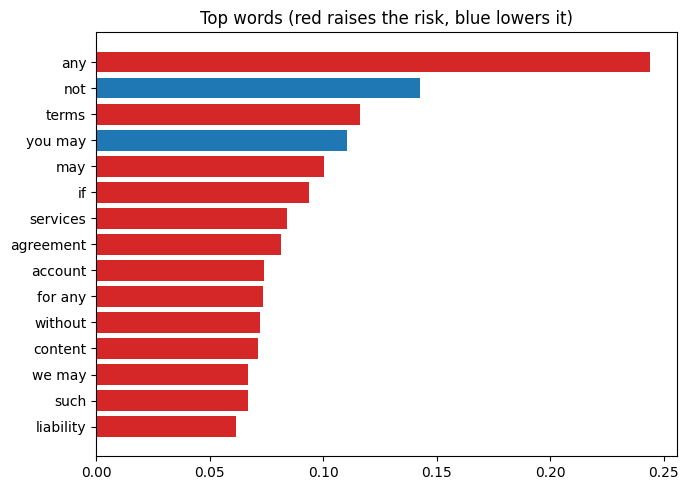

In [ ]:
bg = tfv.transform(tr["text"].sample(500, random_state=42))
Xs = tfv.transform(va["text"].sample(200, random_state=42))

sx = shap.LinearExplainer(clf, shap.maskers.Independent(bg, max_samples=500))
sv = sx.shap_values(Xs)

fw = {"or", "to", "of", "the", "by", "for", "we", "be", "and", "in", "a", "is", "on", "are", "that", "as", "you"}
ok = np.array([not all(t in fw for t in w.split()) for w in wd])

ms = np.abs(sv).mean(axis=0)
ms[~ok] = 0
o = np.argsort(-ms)[:15][::-1]
cl = ["tab:red" if clf.coef_[0][i] > 0 else "tab:blue" for i in o]

plt.figure(figsize=(7, 5))
plt.barh(wd[o], ms[o], color=cl)
plt.title("Top words (red raises the risk, blue lowers it)")
plt.tight_layout()
plt.savefig("shap_global.png", dpi=150)
plt.show()

##Save five demo cases with their explanations

In [ ]:
from xai import Xai

xa = Xai(lr2)

def pick(q, asc):
  d = vx[q].sort_values("p", ascending=asc)
  return d["text"].iloc[0] if len(d) else None

cs = {
  "hit_high": pick((vx["y"] == 1) & (vx["p"] >= thr), False),
  "hit_border": pick((vx["y"] == 1) & (vx["p"] >= thr), True),
  "safe_ok": pick((vx["y"] == 0) & (vx["p"] < thr), True),
  "false_alarm": pick((vx["y"] == 0) & (vx["p"] >= thr), False),
  "miss": pick((vx["y"] == 1) & (vx["p"] < thr), True)
}

rows = []
for k, s in cs.items():
  if s is None:
    continue
  e = xa.explain(s)
  rows.append({
    "case": k,
    "prob": e["prob"],
    "text": s,
    "raises": ", ".join(f'{d["term"]} ({d["push"]})' for d in e["raises"]),
    "lowers": ", ".join(f'{d["term"]} ({d["push"]})' for d in e["lowers"])
  })

xc = pd.DataFrame(rows)
xc.to_csv("xai_cases.csv", index=False)
print(xc.to_string(index=False))

       case  prob                                                                                                                                                                                                                                    text                                                                                                                raises                                                                                                      lowers
   hit_high 1.000 we reserve the right to suspend or deactivate your account or your access to certain aspects or all of the fitbit service , or to terminate these terms , at our sole discretion , at any time and without notice or liability to you .         or (1.371), terminate (1.114), suspend (0.932), liability (0.829), discretion (0.798), without notice (0.605)           at our (-0.151), account or (-0.143), access (-0.141), or to (-0.113), all (-0.088), you (-0.075)
 hit_border 0.332                               

#**Final test and save the files**

## Check the final model on test data and save all the files

In [ ]:
pte = lr2.predict_proba(te["text"])[:, 1]
pr = (pte >= thr).astype(int)
fn = int(((pr == 0) & (te["y"] == 1)).sum())
fp = int(((pr == 1) & (te["y"] == 0)).sum())

mt = {
  "precision": precision_score(te["y"], pr),
  "recall": recall_score(te["y"], pr),
  "f1": f1_score(te["y"], pr),
  "f1_macro": f1_score(te["y"], pr, average="macro"),
  "accuracy": float((pr == te["y"]).mean()),
  "pr_auc": average_precision_score(te["y"], pte),
  "roc_auc": roc_auc_score(te["y"], pte),
  "cost": R * fn + fp
}
print({k: round(float(v), 3) for k, v in mt.items()})
print(confusion_matrix(te["y"], pr))

pd.DataFrame({"y": va["y"].values, "p_lr": plr2, "p_rf": prf2, "p_svm": psvm, "p_avg3": pav}).to_csv("val_probs_classical.csv", index=False)
pd.DataFrame({"y": te["y"].values, "p_lr": pte, "p_rf": rf2.predict_proba(te["text"])[:, 1]}).to_csv("test_probs_classical.csv", index=False)

cfg = {
  "model_file": "lr_tuned.joblib",
  "thr": thr,
  "r": R,
  "target": "y = is_unfair",
  "data": "cleaned unfair_tos: train.csv, val.csv, test.csv",
  "split": "the three files as given"
}
with open("model_config.json", "w") as f:
  json.dump(cfg, f, indent=2)
joblib.dump(lr2, "lr_tuned.joblib")

with mlflow.start_run(run_name="final_lr_test"):
  mlflow.log_params({"model": "logreg_tuned", "thr": thr, "r": R, **b})
  mlflow.log_metrics({f"test_{k}": float(v) for k, v in mt.items()})
  for f_ in ("lr_tuned.joblib", "model_config.json", "val_probs_classical.csv", "test_probs_classical.csv", "xai.py", "xai_cases.csv", "shap_global.png"):
    if os.path.exists(f_):
      mlflow.log_artifact(f_)

{'precision': 0.682, 'recall': 0.86, 'f1': 0.761, 'f1_macro': 0.864, 'accuracy': 0.942, 'pr_auc': 0.875, 'roc_auc': 0.973, 'cost': 189.0}
[[1366   69]
 [  24  148]]


#**Save the model at PKL file**

In [ ]:
import pickle

bundle = {
    "model": lr2,
    "threshold": float(thr)
}

with open("contract_model.pkl", "wb") as f:
    pickle.dump(bundle, f, protocol=pickle.HIGHEST_PROTOCOL)

print("Model saved successfully")

Model saved successfully


#**Make sure that the saved file have the same result**

In [ ]:
with open("contract_model.pkl", "rb") as f:
    loaded = pickle.load(f)

texts = va["text"].iloc[:10].tolist()

same = np.allclose(
    lr2.predict_proba(texts),
    loaded["model"].predict_proba(texts)
)

print("Same predictions:", same)
print("Threshold:", loaded["threshold"])

assert same, "Predictions do not match"

Same predictions: True
Threshold: 0.33


#**Create the requirements.txt file with library versions**

In [ ]:
from importlib.metadata import version
import platform

packages = [
    "scikit-learn",
    "numpy",
    "scipy",
    "joblib",
    "threadpoolctl",
]

with open("requirements.txt", "w") as f:
    for package in packages:
        f.write(f"{package}=={version(package)}\n")

print(open("requirements.txt").read())
print("Python:", platform.python_version())

scikit-learn==1.6.1
numpy==2.1.3
scipy==1.16.3
joblib==1.6.0
threadpoolctl==3.7.0

Python: 3.13.18


#Download both files to your computer

In [ ]:
from google.colab import files

files.download("contract_model.pkl")
files.download("requirements.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>